# Tournament analysis (260914 vs 260723): does preferring the High wall pay in competition?

Analyses the tournament in `~/Unity/Octagon/simulations/tournaments/260914_vs_260723_final`, run by
`agent_training/tournament/run_tournament_260914.ipynb`. 5 models, every ordered pair with mirrors
and with self-matchups = **25 matchups**, 349 trials each. Folder `260914_0020__vs__260723_0034`
means the first model drives agent 0 (P1), the second agent 1 (P2). The winner scores **1.0**
(reached High) or **0.4** (reached Low), the loser 0.

All extraction, statistics and figures come from `analysis/tournament_analysis.py`, shared with the
`260715` and `260723` notebooks; this notebook holds the config and the written-up results.

## The question

`260914` central models take the High wall on every trial (`p_high` 1.000). `260723` central models
take it about 78-84% of the time. The four central entrants are matched on where they stand at trial
start (onset centrality 0.844-0.880), so they differ mainly on which wall they go for.

Self-play cannot settle whether that preference is good play. With both agents on the same policy
each wins about half the trials, so mean score follows from `p_high` by arithmetic
(`0.5 * (0.4 + 0.6 * p_high)` predicts every central model of both batches to within 0.031).
Competition against a *different* policy is the test, because holding out for High can lose the race
to an opponent who banks the nearer Low.

## The field

| entrant | batch | step | p_high | onset centrality | score_rate | path_ratio | role |
| --- | --- | --- | --- | --- | --- | --- | --- |
| `260914_0020` | 260914 | 7,000,371 | 1.000 | 0.870 | 0.488 | 1.151 | central, most typical of its batch |
| `260914_0014` | 260914 | 7,000,221 | 1.000 | 0.880 | 0.473 | 1.159 | central, 2nd most typical |
| `260723_0034` | 260723 | 4,000,042 | 0.838 | 0.880 | 0.444 | 1.129 | central, most typical of its batch |
| `260723_0039` | 260723 | 4,000,088 | 0.773 | 0.844 | 0.432 | 1.116 | central |
| `260914_0017` | 260914 | 7,000,223 | 0.965 | 0.140 | 0.369 | 1.399 | off-cluster |

**This notebook covers**
1. **Run validation** — are the matchups complete and fair (self-matchups near 50%, mirror-consistent)?
2. **Per-run results + head-to-head matrices** — the outcome of each matchup; raw score and win-rate matrices.
3. **Overall ranking** — mean score per trial, total accumulated score, win rate, and a Bradley-Terry strength, per model.
4. **Score decomposition** — mean score split into how often a model wins and which wall it wins, which is where the High-preference question lives.
5. **Pair interaction** — how much each head-to-head deviates from what the models' overall strengths predict, plus a non-transitivity check.
6. **Reward** — the same ranking on reward instead of score, and whether efficiency reorders the models.

> **Build note.** The tournament build is `build_260909_01_tournament_nosteppenalty`, with the
> no-movement penalty break absent. Both batches were trained with the break absent too, so the
> tournament reward structure matches the training reward structure for either group. This is the
> same situation as `260723` and unlike `260715`, where the builds disagreed.

### Two assumptions to hold in mind

**1. Entrants are at their own batch's finished policy, not at a matched step count.** `260914` sits
at ~7.0e6 steps, `260723` at ~4.0e6. The run notebook argues this is the fair comparison: `260723`
converged by about 3e6 and its linear schedule then annealed the learning rate to a stop, so extra
steps cannot improve it, while `260914` uses a constant learning rate and is still improving at 7e6.
Matching at 4e6 would pit a converged model against one running mid-flight.

The cost is that a batch difference here carries training length inside it. Step-matching at 4e6
already showed this matters: the `260914` self-play score lead (0.501 vs 0.462) vanished at matched
steps (0.457 vs 0.459) despite `p_high` staying at 1.000 vs 0.806. So the extra training, not the
wall preference, produced that lead.

Section 4 is built to separate the two. Training length buys general strength, which shows up as
**win rate**. The wall preference shows up as **value per win**. A `260914` lead that sits entirely
in win rate is the confound again; one that sits in value per win is the answer to the question.

**2. High share is measured over won trials only.** The log records the wall that ended the trial,
so only the winner's choice is observable. A model that raced for High and lost leaves no record of
what it was going for. Recovering that needs `analysis/loser_inferred_choice.py`, which infers the
loser's target from its trajectory, and is left to a separate notebook.

In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import analysis.tournament_analysis as ta

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 220)

BASE = os.path.expanduser('~/Unity/Octagon/simulations/tournaments/260914_vs_260723_final')

# Entrants and their group. A model id is the integer part of its run id, so 20 is 260914_0020
# and 34 is 260723_0034. The five ids are unique across the two batches in this field.
# The grouping is the batch, not a strategy band, because the batch contrast is the question.
GROUP = {20: '260914 central', 14: '260914 central',
         34: '260723 central', 39: '260723 central',
         17: '260914 off-cluster'}

# Group order sets the row/column order of every matrix and the legend order. Off-cluster last,
# so the matrices read with the High-preference contrast first.
GROUP_ORDER = ['260914 central', '260723 central', '260914 off-cluster']
GROUP_PALETTE = {'260914 central': '#4C72B0',       # blue
                 '260723 central': '#DD8452',       # orange
                 '260914 off-cluster': '#7F7F7F'}   # grey, to keep it out of the batch contrast

MODELS = ta.models_in_order(GROUP, GROUP_ORDER)     # grouped by batch, in the order above

RUN_ID = {20: '260914_0020', 14: '260914_0014',     # for reading the figures back to run ids
          34: '260723_0034', 39: '260723_0039', 17: '260914_0017'}

STEP_PENALTY = 0.001    # for reference; reward = score - STEP_PENALTY * action_steps

## Main pass — load every matchup

Loads each of the 25 matchups (~5 s each), extracts per-trial outcomes, and stacks them into one
long table. Also reports which matchups are missing `DONE.txt`. The `_smoke_test` folder has no
`__vs__` in its name, so it is skipped.

In [2]:
# One row per completed trial per matchup: both models, the winning client, each model's
# score and reward, and the wall separation.
trials_df = ta.load_tournament(BASE)
per_matchup = ta.per_matchup_summary(trials_df)

# One row per (focus model, opponent) per trial, so both seat orders pool. Self-matchups are
# dropped, since a model cannot out-rank itself. Every trial appears twice, once from each
# model's side, so index this table by focus.
selfless = ta.perspective_table(trials_df)

260723_0034__vs__260723_0034 done  

260723_0034__vs__260723_0039 done  

260723_0034__vs__260914_0014 done  

260723_0034__vs__260914_0017 done  

260723_0034__vs__260914_0020 done  

...

260914_0020__vs__260723_0034 done  

260914_0020__vs__260723_0039 done  

260914_0020__vs__260914_0014 done  

260914_0020__vs__260914_0017 done  

260914_0020__vs__260914_0020 done  

matchups loaded: 25 / 25   trials: 8725
trials per matchup: min 349, max 349


## 1. Run validation

Before trusting any ranking, confirm the tournament is fair:
- **Self-matchups** (a model vs a copy of itself) should sit near **0.5** — far from it means a seat or agent asymmetry, the failure mode of the first `260715` run, where the opponent never moved.
- **Mirror consistency** — a model's win rate against an opponent should be the same whether it played P1 or P2. Large gaps mean the seat still matters. `260715` came out at a mean gap of 0.018.
- **Winner-take-all** — exactly one agent scores each trial. The score decomposition in section 4 relies on this, since it assumes a loss pays 0.

In [3]:
ta.validation_report(trials_df, per_matchup, MODELS);

Self-matchup P1 win rate (should be ~0.5):
 model   n  p1_win_rate
    34 349        0.510
    39 349        0.481
    14 349        0.479
    17 349        0.501
    20 349        0.415
  mean 0.477, worst deviation from 0.5: 0.085

Mirror consistency over 10 pairs, mean gap 0.038, max 0.095
    pair  A_asP1  A_asP2   gap
34 vs 17   0.782   0.688 0.095
20 vs 39   0.430   0.510 0.080
14 vs 34   0.504   0.444 0.060
34 vs 39   0.493   0.447 0.046
14 vs 17   0.725   0.751 0.026

winner-take-all (exactly one agent scores per trial): 1.000 of trials
reward range: [-0.725, 0.716]  (negative = moved and lost)


In [4]:
# every matchup should carry the same trial count, since one predetermined trial sequence is
# replayed for all of them
print(per_matchup.n.value_counts().to_string())

# the first logged trial is dropped by convention, and a final trial with no trial end cannot
# survive the trigger/trial-end merge, so check what each matchup actually kept
first_last = trials_df.groupby('matchup').trial_num.agg(['min', 'max'])
print(f"\ntrial_num kept per matchup: first {first_last['min'].unique()}, "
      f"last {first_last['max'].unique()}")

n
349    25

trial_num kept per matchup: first [1.], last [349.]


## 2. Per-run results and head-to-head

Each matchup's outcome, then the pooled head-to-head matrices. Pooling both seat orders (A-vs-B and
B-vs-A) gives a seat-balanced estimate of how each model does against each opponent.

The six cross-batch central cells are the ones that answer the question: models 20 and 14 against
models 34 and 39.

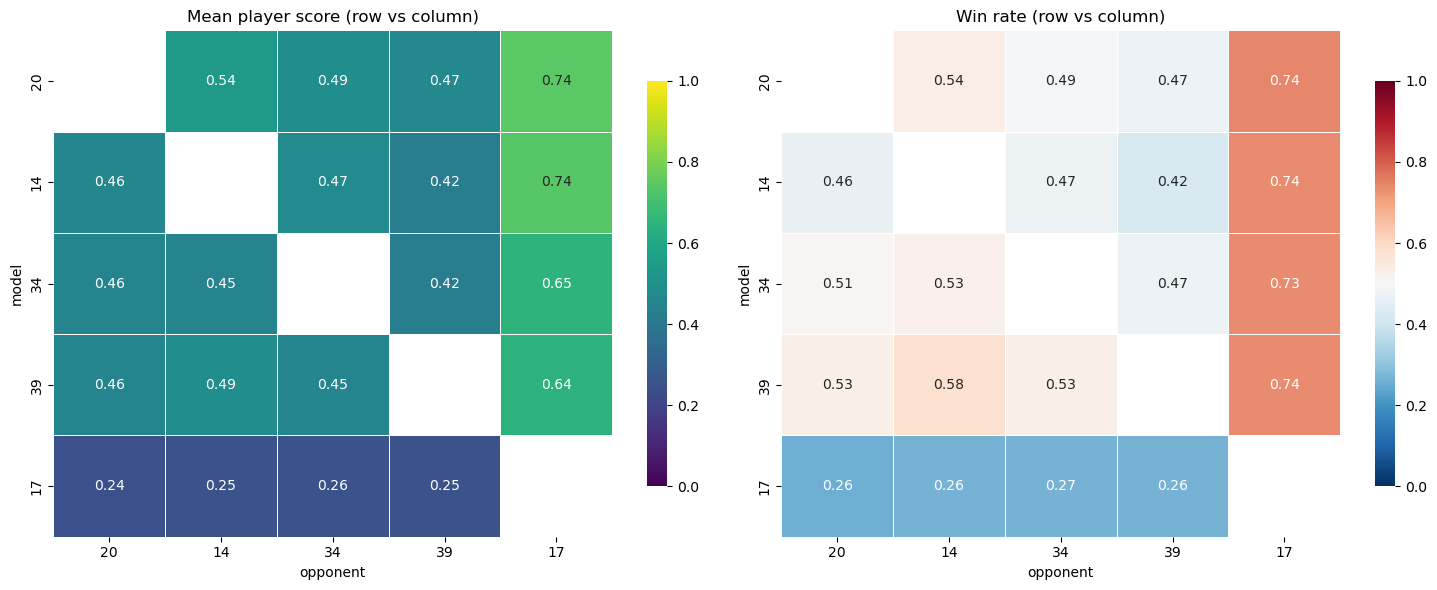

Per-matchup results (ordered A=P1 vs B=P2):


,matchup,model_A,model_B,n,p1_win_rate,mean_score_A,mean_score_B,mean_reward_A,mean_reward_B
0,260723_0034__vs__260723_0034,34,34,349,0.510,0.462,0.447,0.007,-0.007
1,260723_0034__vs__260723_0039,34,39,349,0.493,0.431,0.438,-0.020,-0.013
2,260723_0034__vs__260914_0014,34,14,349,0.556,0.477,0.444,0.021,-0.012
3,260723_0034__vs__260914_0017,34,17,349,0.782,0.688,0.207,0.233,-0.247
4,260723_0034__vs__260914_0020,34,20,349,0.521,0.460,0.479,0.006,0.025
5,260723_0039__vs__260723_0034,39,34,349,0.553,0.469,0.406,0.017,-0.046
6,260723_0039__vs__260723_0039,39,39,349,0.481,0.414,0.448,-0.036,-0.003
7,260723_0039__vs__260914_0014,39,14,349,0.587,0.491,0.413,0.038,-0.041
8,260723_0039__vs__260914_0017,39,17,349,0.736,0.630,0.252,0.178,-0.200
9,260723_0039__vs__260914_0020,39,20,349,0.490,0.419,0.510,-0.031,0.060


In [5]:
# Mirror-pooled matrices, read row-model against column-opponent.
mats = ta.head_to_head(selfless, MODELS)
ta.plot_head_to_head(mats)
plt.show()

print("Per-matchup results (ordered A=P1 vs B=P2):")
per_matchup.round(3)

## 3. Overall ranking

Which models are most successful, over all opponents (self-matchups excluded). The focus is **mean
score per trial**; total accumulated score and win rate are also shown, plus a Bradley-Terry
strength fit from the win/loss counts.

Read this as a ranking, not yet as an answer. Mean score combines two different things, and section
4 separates them.

Overall ranking by mean score:
 rank  model           strategy  mean_score  total_score  win_rate  bt_strength
    1     20     260914 central       0.561       1566.0     0.561        1.149
    2     14     260914 central       0.523       1460.0     0.523        1.012
    3     39     260723 central       0.510       1425.2     0.595        1.289
    4     34     260723 central       0.493       1377.4     0.560        1.146
    5     17 260914 off-cluster       0.250        697.2     0.261        0.405


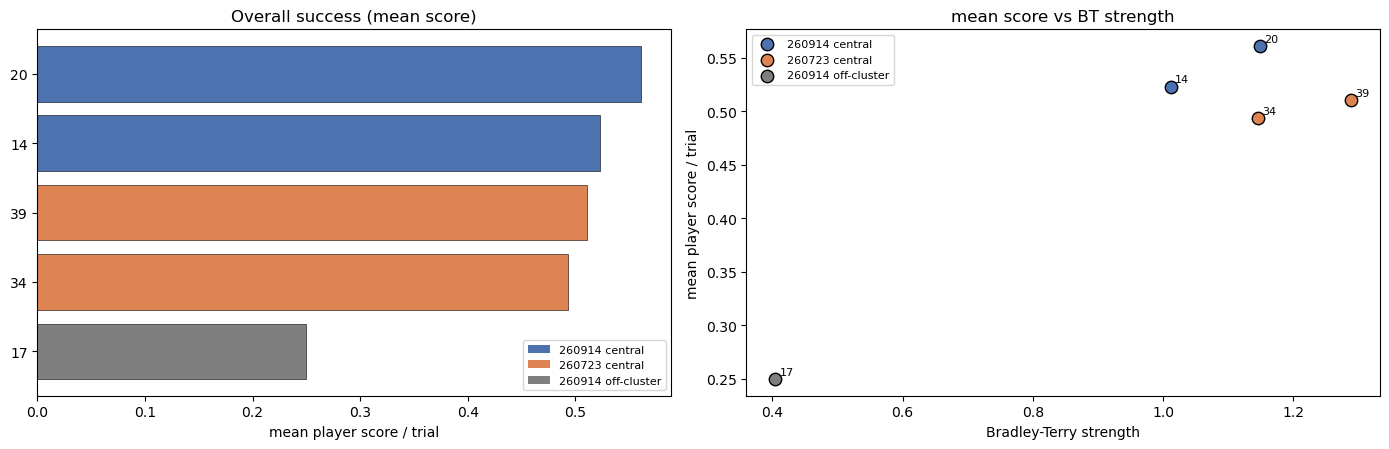

In [6]:
overall = ta.overall_ranking(selfless, GROUP, MODELS, sort_by='mean_score')
ta.plot_overall_ranking(overall, metric='mean_score', palette=GROUP_PALETTE,
                        strat_order=GROUP_ORDER)
plt.show()

## 4. Score decomposition — winning often vs winning the valuable wall

A trial pays the winner 1.0 at High and 0.4 at Low, and the loser 0, so

`mean score = win rate x value per win`

exactly. The two factors are different things. **Win rate** is how often the model gets to a wall
first, and is what general strength (including extra training) buys. **Value per win** is which wall
it got to, and is where High preference shows up: 1.0 means every win was taken at High, 0.4 means
every win was taken at Low.

The three outcomes to tell apart:
- `260914` leads on **win rate** with the same value per win — the lead is general strength, so the training-length confound is back and the wall preference is not doing the work.
- `260914` leads on **value per win** at equal or lower win rate — holding out for High pays, which is the result the tournament was run to find.
- `260914` leads on value per win but loses more races — the preference costs as much as it earns, and the net shows in mean score.

Mean score split into win rate x value per win:
 model           strategy  mean_score  win_rate  win_rate_se  value_per_win  high_share  score_rank  win_rate_rank  rank_shift  n_trials
    20     260914 central       0.561     0.561        0.009          1.000       1.000           1              2          -1      2792
    14     260914 central       0.523     0.523        0.009          1.000       1.000           2              4          -2      2792
    39     260723 central       0.510     0.595        0.009          0.858       0.763           3              1           2      2792
    34     260723 central       0.493     0.560        0.009          0.881       0.801           4              3           1      2792
    17 260914 off-cluster       0.250     0.261        0.008          0.956       0.927           5              5           0      2792

identity check, max |win_rate x value_per_win - mean_score|: 2.78e-17
4 of 5 models rank differently on win rate alone: 20 (-1), 

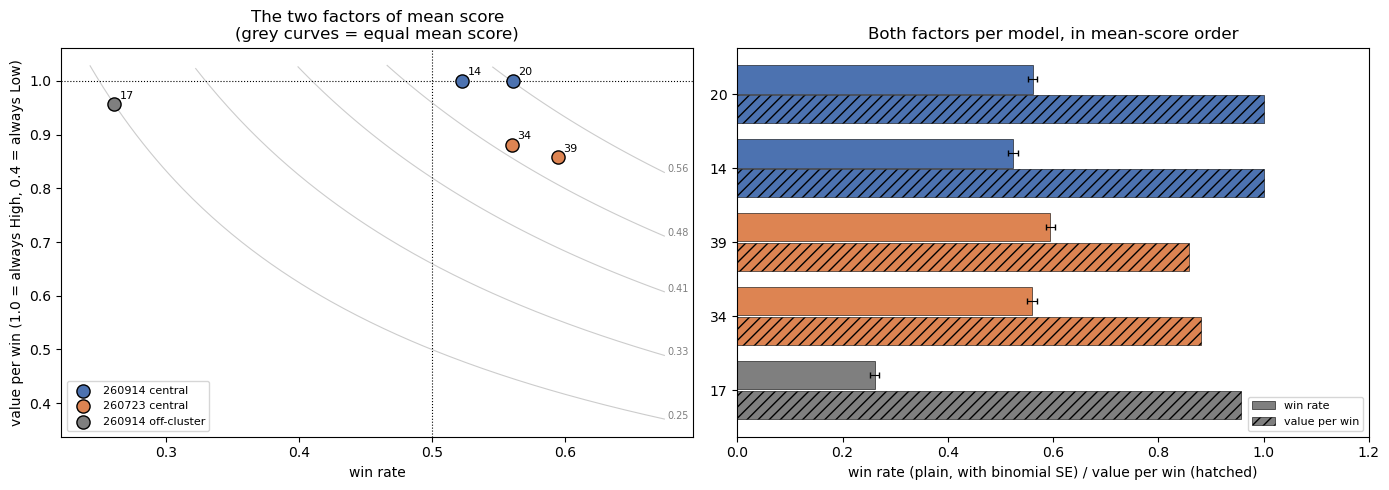

In [7]:
# Mean score split into its two factors, per model and pooled by group.
decomp = ta.score_decomposition(selfless, GROUP, MODELS, order=GROUP_ORDER)
print()
groups = ta.group_summary(selfless, GROUP, order=GROUP_ORDER)

ta.plot_score_decomposition(decomp, palette=GROUP_PALETTE, strat_order=GROUP_ORDER)
plt.show()

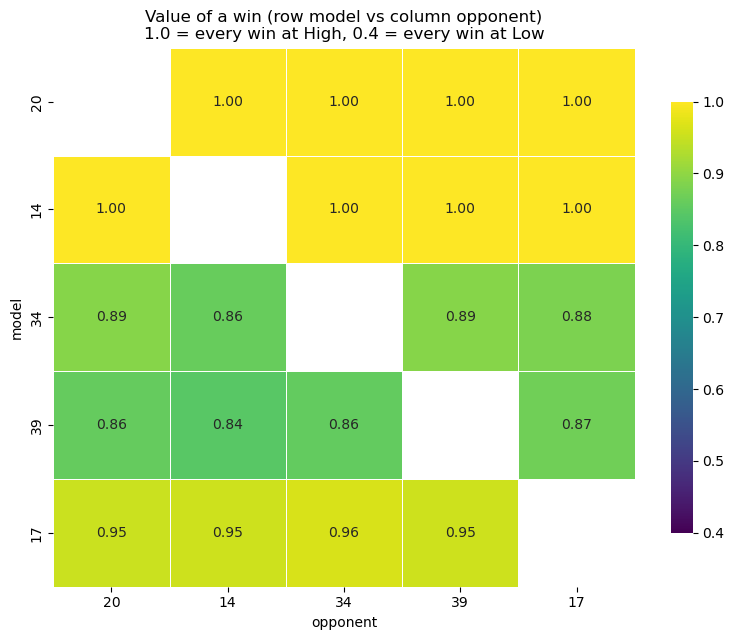

In [8]:
# Which wall each model reaches when it wins, per opponent. A model whose High preference
# survives a fast opponent holds its row near 1.0 across every column.
vpw = ta.value_per_win(mats)
ta.plot_value_per_win(vpw)
plt.show()

In [9]:
# The two factors restricted to the four central models, where onset centrality is matched and
# the batches differ mainly on High preference. Model 17 is dropped from both sides, so neither
# batch is credited with beating it.
central = [m for m in MODELS if GROUP[m] != '260914 off-cluster']
central_only = selfless[selfless.focus.isin(central) & selfless.opp.isin(central)]

print("Central models only, off-cluster opponent excluded:")
ta.score_decomposition(central_only, GROUP, central, order=GROUP_ORDER)
print()
ta.group_summary(central_only, GROUP, order=GROUP_ORDER);

Central models only, off-cluster opponent excluded:
Mean score split into win rate x value per win:
 model       strategy  mean_score  win_rate  win_rate_se  value_per_win  high_share  score_rank  win_rate_rank  rank_shift  n_trials
    20 260914 central       0.500     0.500        0.011          1.000       1.000           1              3          -2      2094
    39 260723 central       0.467     0.547        0.011          0.853       0.755           2              1           1      2094
    14 260914 central       0.451     0.451        0.011          1.000       1.000           3              4          -1      2094
    34 260723 central       0.442     0.502        0.011          0.881       0.801           4              2           2      2094

identity check, max |win_rate x value_per_win - mean_score|: 5.55e-17
4 of 4 models rank differently on win rate alone: 20 (-2), 39 (+1), 14 (-1), 34 (+2)

Pooled over trials, by group:
      strategy  n_trials  n_models  win_rate  me

## 5. Does the pairing matter? (interaction)

If success were purely each model's general strength, every head-to-head would be predicted by the
two Bradley-Terry strengths. The **residual** (actual win rate minus BT-predicted) is the part
explained by the specific pairing. Large residuals, or non-transitive loops (A beats B beats C beats
A), mean the matchup itself matters, not just overall strength. `260715`: RMS residual 0.034, zero
loops. A strategy clash between the two batches would show up here as a block of same-signed
residuals in the cross-batch cells.

Interaction (actual - BT-predicted win rate): RMS residual 0.013, max |residual| 0.023
Non-transitive triples (rock-paper-scissors loops): 0 of 10


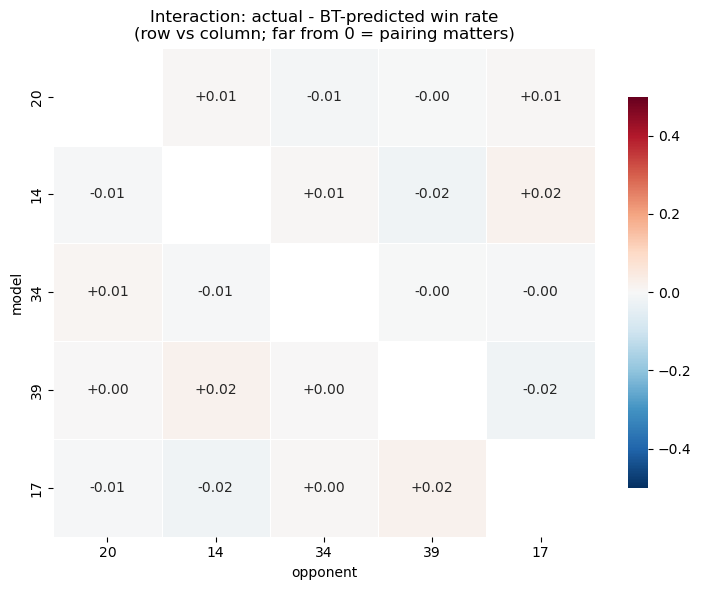

In [10]:
bt = ta.bradley_terry(selfless, MODELS)
resid = ta.interaction(mats['win'], bt, MODELS, strategy=GROUP)
ta.plot_interaction(resid)
plt.show()

## 6. Reward — does efficiency reorder the models?

- **score** = terminal outcome (winner 1.0 High / 0.4 Low, loser 0).
- **reward** (`trialRewards`) = score − step_penalty × episode steps.

The tournament build's reward structure matches both batches' training builds, so this ranking
reflects the landscape the models were optimised under. Episode length is pinned by the
predetermined trial sequence and symmetric between the two competitors, so if the per-model movement
cost comes out near-constant, reward will add nothing over score. That would be a result about these
models, not an artefact.

Model 17 is the one to watch here. It is the slowest of its batch to reach a wall and takes the
longest route (`path_ratio` 1.399 against ~1.15), so it should pay the largest movement cost.

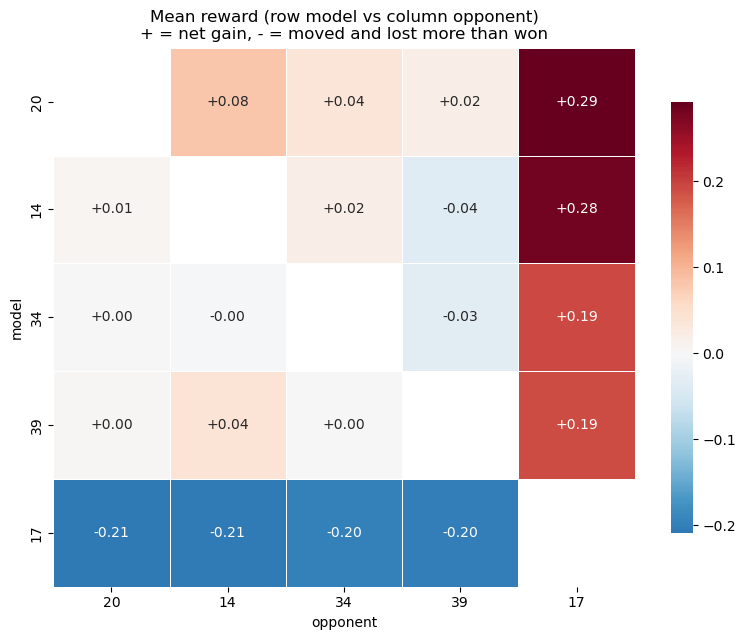

Overall ranking by mean reward:
 rank  model           strategy  mean_reward  mean_score  win_rate  bt_strength
    1     20     260914 central        0.108       0.561     0.561        1.149
    2     14     260914 central        0.068       0.523     0.523        1.012
    3     39     260723 central        0.059       0.510     0.595        1.289
    4     34     260723 central        0.040       0.493     0.560        1.146
    5     17 260914 off-cluster       -0.204       0.250     0.261        0.405


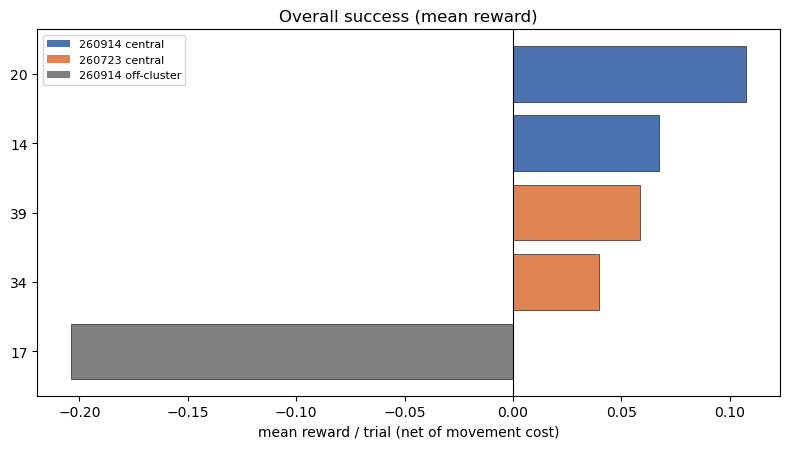

In [11]:
ta.plot_reward_head_to_head(mats)
plt.show()

# Same table as above, ranked on reward instead. Wins, and so the Bradley-Terry strengths,
# are identical either way: reward changes the value of a trial, not its winner.
overall_reward = ta.overall_ranking(selfless, GROUP, MODELS, sort_by='mean_reward')
ta.plot_overall_ranking(overall_reward, metric='mean_reward', palette=GROUP_PALETTE,
                        strat_order=GROUP_ORDER, with_bt=False)
plt.show()

Score vs reward (rank_shift > 0 = model climbs when judged on reward):
 model           strategy  mean_score  mean_reward  score_rank  reward_rank  rank_shift  cost
    20     260914 central       0.561        0.108           1            1           0 0.453
    14     260914 central       0.523        0.068           2            2           0 0.455
    39     260723 central       0.510        0.059           3            3           0 0.452
    34     260723 central       0.493        0.040           4            4           0 0.454
    17 260914 off-cluster       0.250       -0.204           5            5           0 0.453


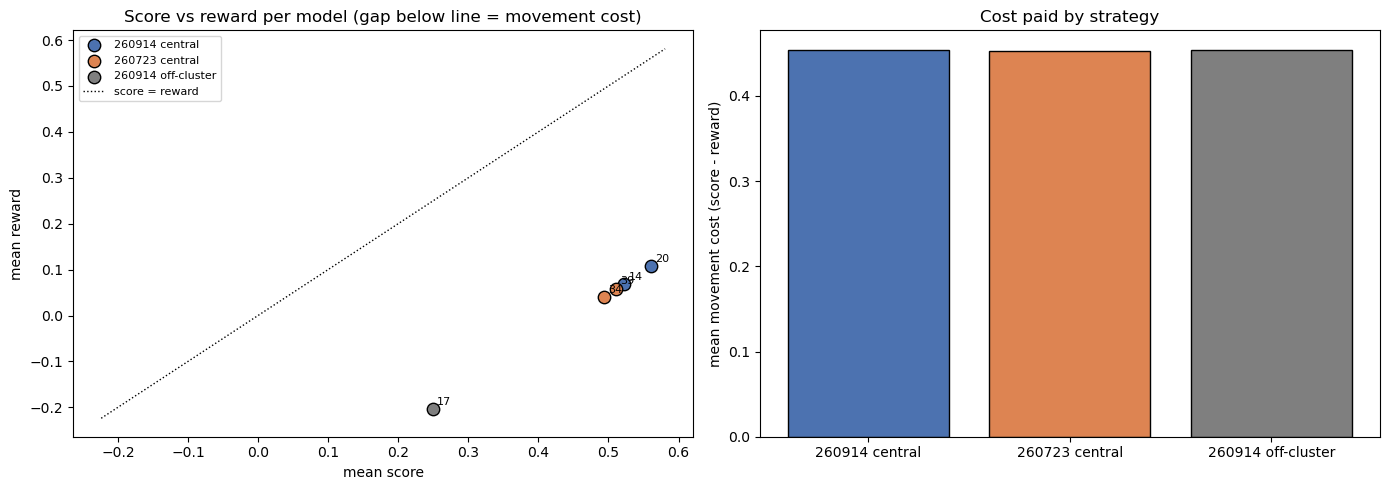

In [12]:
cmp = ta.score_vs_reward(overall)
ta.plot_score_vs_reward(cmp, palette=GROUP_PALETTE, strat_order=GROUP_ORDER)
plt.show()

## What came out

**The run is sound.** All 25 matchups finished at 349 trials, exactly one agent scores every trial,
and every matchup keeps trials 1-349. Self-matchups average 0.477, with model 20 the worst at 0.415
(0.085 off an even split, about 3 binomial SE). Mirror gaps average 0.038 and reach 0.095, larger
than `260715`'s 0.018. Both are seat effects, and pooling the two seat orders removes them from
every cross-pair number, so the head-to-head and ranking results stand. The residual wobble is worth
remembering when reading a single cell to three decimal places.

**High preference pays, and it pays by losing races.** Pooled over all opponents, `260914` central
wins *fewer* trials than `260723` central (win rate 0.542 against 0.578) but scores more per trial
(0.542 against 0.502). Every `260914` win is taken at High (value per win 1.000) against 0.869 for
`260723`. Restricted to the four central models, where onset centrality is matched and model 17 is
out of the field, the same picture holds: win rate 0.475 against 0.525, value per win 1.000 against
0.866, mean score 0.475 against 0.454. The two group win rates sum to 1 there because the field is
symmetric, so that number is the cross-batch races read from both sides.

**This is not the training-length confound.** The worry going in was that `260914`'s extra 3e6 steps
would buy general strength and show up as a score lead. General strength wins races, and races are
where `260914` trails. Its entire score advantage sits in the value of a win, which is the wall
preference. What the extra training cannot be cleared of is whether it is what made an all-High
policy affordable in the first place.

**The ranking depends on which factor is read.** Model 39 has the highest win rate (0.595) and the
highest Bradley-Terry strength (1.289) but ranks 3rd on score. Model 20 ranks 1st on score and 2nd
on win rate. 4 of the 5 models change rank between the two, so a tournament ranked on score alone
would have hidden the mechanism entirely.

**The pairing barely matters.** RMS interaction residual 0.013, max 0.023, and 0 of 10 non-transitive
loops. A transitive strength ladder with no rock-paper-scissors, and no sign of a strategy clash
between the batches beyond what their overall strengths already predict.

**Reward reorders nothing.** Every model pays a movement cost of 0.452-0.455 and `rank_shift` is 0
across the board. Episode length is pinned by the predetermined trial sequence and the penalty is
charged per step, so the cost is the same even for model 17, whose `path_ratio` of 1.399 says it
travels much further.

**Model 17 is last by a wide margin** (win rate 0.261, mean score 0.250). Its own High share of 0.927
does not rescue it, which is the other side of the same finding: preferring High only pays once a
model can win races.

## Reading the results

- **Validation** — trust the rest only if self-matchups sit near 0.5 and mirror gaps are small.
- **Overall ranking** — mean score per trial, with BT strength tracking it closely. Colour shows whether a batch dominates, but mean score alone cannot say why.
- **Decomposition** — the answer to the question. A `260914` advantage in value per win means holding out for High pays in competition. An advantage only in win rate means the extra training steps, not the wall preference. Read the central-only table as well as the full field, since model 17 is a weaker opponent that both batches beat.
- **Interaction** — a small RMS residual and no non-transitive loops means success is essentially each model's general strength, and the pairing adds little. A same-signed block in the cross-batch cells would mean the two batches' strategies clash in a way their overall strengths do not capture.
- **Reward** — a `rank_shift` of 0 for every model means the movement cost is constant across models and reward is score minus that constant. A non-zero shift means cheap play buys rank.

Per-separation analysis (using the `sep` column), the loser's inferred wall choice, and behavioural
characterisation of the races are left to separate notebooks.